In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import os

import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms

In [2]:
class Phase1DataAcquisition:
    def __init__(self, data_root="./data", image_size=224):
        self.data_root = Path(data_root)
        self.custom_dir = self.data_root / "custom_images"
        self.data_root.mkdir(parents=True, exist_ok=True)
        self.custom_dir.mkdir(parents=True, exist_ok=True)
        self.image_size = image_size

        self.train_transform = transforms.Compose([
            transforms.Resize((self.image_size, self.image_size)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=10),
            transforms.ColorJitter(brightness=0.15, contrast=0.15),
            transforms.ToTensor(),
        ])

        self.eval_transform = transforms.Compose([
            transforms.Resize((self.image_size, self.image_size)),
            transforms.ToTensor(),
        ])

    def download_torchvision_datasets(self):
        cifar_train = datasets.CIFAR10(
            root=str(self.data_root), train=True, download=True
        )
        cifar_test = datasets.CIFAR10(
            root=str(self.data_root), train=False, download=True
        )

        print(f"Data root: {self.data_root.resolve()}")
        print(f"CIFAR-10 train size: {len(cifar_train)}")
        print(f"CIFAR-10 test size: {len(cifar_test)}")
        return cifar_train, cifar_test

    def download_images(self, image_urls):
        for file_name, url in image_urls.items():
            target_path = self.custom_dir / file_name
            if target_path.exists():
                print(f"Already exists: {target_path}")
                continue

            print(f"Downloading: {file_name}")
            try:
                urlretrieve(url, target_path)
                with Image.open(target_path) as image:
                    image.verify()
                print(f"Saved to: {target_path}")
            except Exception as error:
                if target_path.exists():
                    target_path.unlink()
                print(f"Could not download {file_name}: {error}")

        return sorted(self.custom_dir.glob("*"))

    def inspect_images(self):
        custom_files = sorted(self.custom_dir.glob("*"))
        print(f"Custom image count: {len(custom_files)}")
        for path in custom_files:
            try:
                with Image.open(path) as image:
                    print(
                        f"{path.name}: size={image.size}, mode={image.mode}, "
                        f"bytes={os.path.getsize(path)}"
                    )
            except Exception as error:
                print(f"Skipping {path.name}: {error}")
        return custom_files

    def show_custom_images(self):
        custom_files = []
        for path in sorted(self.custom_dir.glob("*")):
            try:
                with Image.open(path) as image:
                    image.verify()
                custom_files.append(path)
            except Exception:
                pass

        if not custom_files:
            print("Ko'rsatish uchun rasm topilmadi. Avval download_images() ni ishlating.")
            return

        fig, axes = plt.subplots(1, len(custom_files), figsize=(5 * len(custom_files), 4))
        if len(custom_files) == 1:
            axes = [axes]
        for ax, path in zip(axes, custom_files):
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(path.name)
            ax.axis("off")
        plt.tight_layout()
        plt.show()

    def show_cifar_samples(self, dataset, count=5):
        count = min(count, len(dataset))
        fig, axes = plt.subplots(1, count, figsize=(3 * count, 3))
        if count == 1:
            axes = [axes]
        for index, ax in enumerate(axes):
            image, label = dataset[index]
            ax.imshow(image)
            ax.set_title(f"label={label}")
            ax.axis("off")
        plt.suptitle("CIFAR-10 Samples")
        plt.tight_layout()
        plt.show()


In [3]:
data_manager = Phase1DataAcquisition(data_root="./data", image_size=224)
print(f"Data root: {data_manager.data_root.resolve()}")
print(f"Custom image folder: {data_manager.custom_dir.resolve()}")

Data root: /Users/asadbek/Documents/machine-learning/deep_learning/CV/lesson-3/data
Custom image folder: /Users/asadbek/Documents/machine-learning/deep_learning/CV/lesson-3/data/custom_images


Data root: /Users/asadbek/Documents/machine-learning/deep_learning/CV/lesson-3/data
CIFAR-10 train size: 50000
CIFAR-10 test size: 10000


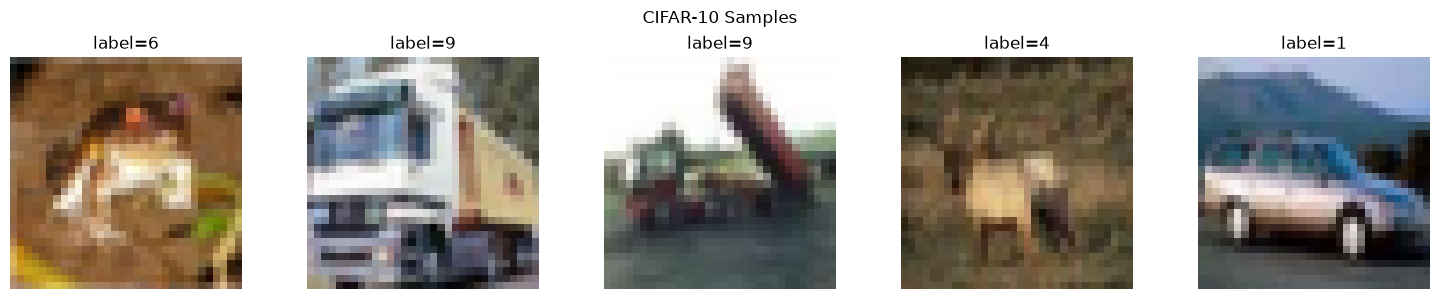

In [4]:
cifar_train, cifar_test = data_manager.download_torchvision_datasets()
data_manager.show_cifar_samples(cifar_train, count=5)

In [ ]:
image_urls = {
    "cat.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg",
    "building.jpg": "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg",
    "scene.jpg": "https://raw.githubusercontent.com/pytorch/hub/master/images/deeplab1.png",
}

custom_files = data_manager.download_images(image_urls)

Downloading: cat.jpg
Saved to: data/custom_images/cat.jpg
Downloading: building.jpg
Saved to: data/custom_images/building.jpg
Downloading: scene.jpg
Saved to: data/custom_images/scene.jpg


Custom image count: 3
building.jpg: size=(1546, 1213), mode=RGB, bytes=661378
cat.jpg: size=(512, 512), mode=RGB, bytes=91814
scene.jpg: size=(1282, 1026), mode=RGBA, bytes=2487681


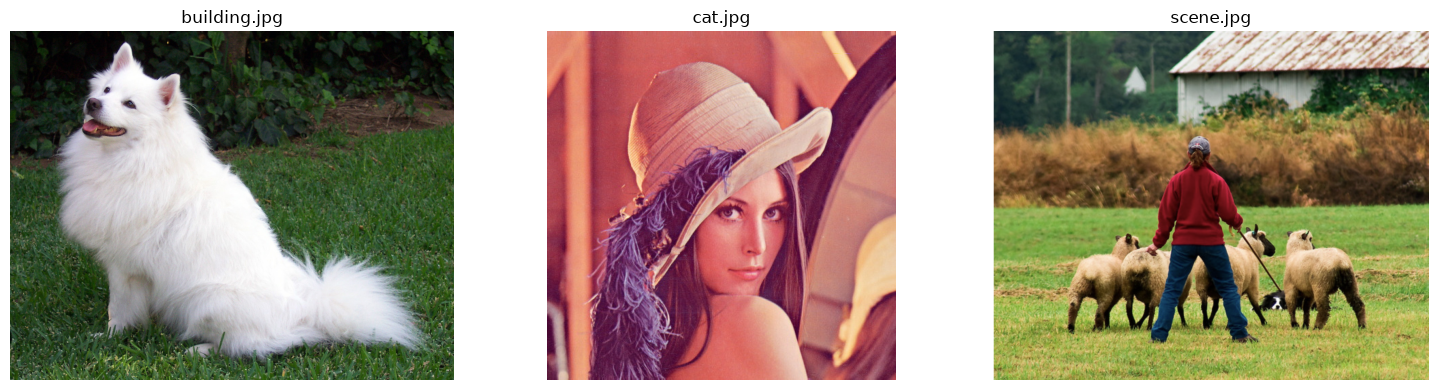

In [6]:
data_manager.inspect_images()
data_manager.show_custom_images()

In [7]:
cifar_train_augmented = datasets.CIFAR10(
    root=str(data_manager.data_root),
    train=True,
    download=True,
    transform=data_manager.train_transform,
)

cifar_test_processed = datasets.CIFAR10(
    root=str(data_manager.data_root),
    train=False,
    download=True,
    transform=data_manager.eval_transform,
)

image_tensor, label = cifar_train_augmented[0]
print("Augmented tensor shape:", tuple(image_tensor.shape))
print("Label:", label)

Augmented tensor shape: (3, 224, 224)
Label: 6
